## NBA Points Predictor - Normal Bayesian Model
**- Owner:** Alex

**- Status:** Exploration only

**- Last Updated:** 10/27/26

In [1]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

ROOT = Path("/Users/alexgonzalez/Documents/nba_quant")
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

Matplotlib is building the font cache; this may take a moment.


In [2]:
s20 = pd.read_parquet('/Users/alexgonzalez/Documents/nba_quant/data/silver/nba/2019-20/regular_season/player_gamelogs.parquet')
s21 = pd.read_parquet('/Users/alexgonzalez/Documents/nba_quant/data/silver/nba/2020-21/regular_season/player_gamelogs.parquet')
s22 = pd.read_parquet('/Users/alexgonzalez/Documents/nba_quant/data/silver/nba/2021-22/regular_season/player_gamelogs.parquet')
s23 = pd.read_parquet('/Users/alexgonzalez/Documents/nba_quant/data/silver/nba/2022-23/regular_season/player_gamelogs.parquet')
s24 = pd.read_parquet('/Users/alexgonzalez/Documents/nba_quant/data/silver/nba/2023-24/regular_season/player_gamelogs.parquet')
s25 = pd.read_parquet('/Users/alexgonzalez/Documents/nba_quant/data/silver/nba/2024-25/regular_season/player_gamelogs.parquet')
s26 = pd.read_parquet('/Users/alexgonzalez/Documents/nba_quant/data/silver/nba/2025-26/regular_season/player_gamelogs.parquet')
s27 = pd.read_parquet('/Users/alexgonzalez/Documents/nba_quant/data/silver/nba/2026-27/regular_season/player_gamelogs.parquet')
df = pd.concat([s20, s21, s22, s23, s24, s25, s26, s27]).reset_index(drop=True)
df['starting'] = (
    df['start_position'].astype('string').str.strip().isin(['G', 'F', 'C']).astype(int))
print(f"Number of rows: {len(df)}")
print(f"Number of columns: {len(df.columns)}")
print(df.columns.tolist())
print(df.dtypes)
print(df.head().to_string())

Number of rows: 177919
Number of columns: 190
['season_year', 'player_id', 'player_name', 'nickname', 'team_id', 'team_abbreviation', 'team_name', 'game_id', 'game_date', 'matchup', 'wl', 'min', 'fgm', 'fga', 'fg_pct', 'fg3_m', 'fg3_a', 'fg3_pct', 'ftm', 'fta', 'ft_pct', 'oreb', 'dreb', 'reb', 'ast', 'tov', 'stl', 'blk', 'blka', 'pf', 'pfd', 'pts', 'plus_minus', 'nba_fantasy_pts', 'dd2', 'td3', 'wnba_fantasy_pts', 'fp_high_score', 'available_flag', 'min_sec', 'team_count', 'e_off_rating', 'off_rating', 'sp_work_off_rating', 'e_def_rating', 'def_rating', 'sp_work_def_rating', 'e_net_rating', 'net_rating', 'sp_work_net_rating', 'ast_pct', 'ast_to', 'ast_ratio', 'oreb_pct', 'dreb_pct', 'reb_pct', 'tm_tov_pct', 'e_tov_pct', 'efg_pct', 'ts_pct', 'usg_pct', 'e_usg_pct', 'e_pace', 'pace', 'pace_per40', 'sp_work_pace', 'pie', 'poss', 'fgm_pg', 'fga_pg', 'team_city', 'team_tricode', 'team_slug', 'first_name', 'family_name', 'name_i', 'player_slug', 'start_position', 'comment', 'jersey_num', 'mi

In [3]:
PLAYER_NAME = 'Julius Randle'
LINE = 19.5

data = df[df['player_name'] == PLAYER_NAME]
data.tail(5)

,season_year,player_id,player_name,nickname,team_id,team_abbreviation,team_name,game_id,game_date,matchup,...,opp_pace,opp_pace_per40,opp_poss,opp_pie,season_type,pos,game_total,team_spread,player_team_spread,starting
176133,2025-26,203944,Julius Randle,Julius,1610612750,MIN,Minnesota Timberwolves,0022500019,2025-10-24T00:00:00,MIN @ LAL,...,93.5,77.92,93,0.614,Regular Season,PF,226.0,1.5,-1.5,1
176450,2025-26,203944,Julius Randle,Julius,1610612750,MIN,Minnesota Timberwolves,0022500089,2025-10-22T00:00:00,MIN @ POR,...,104.0,86.67,103,0.489,Regular Season,PF,222.5,4.5,-4.5,1
176982,2026-27,203944,Julius Randle,Julius,1610612751,BKN,Brooklyn Nets,0022600113,2026-10-25T00:00:00,BKN vs. IND,...,105.0,87.50,105,0.627,Regular Season,PF,231.5,5.5,5.5,1
177139,2026-27,203944,Julius Randle,Julius,1610612751,BKN,Brooklyn Nets,0022600105,2026-10-24T00:00:00,BKN @ CLE,...,107.0,89.17,107,0.573,Regular Season,PF,228.5,-11.0,11.0,1
177602,2026-27,203944,Julius Randle,Julius,1610612751,BKN,Brooklyn Nets,0022600087,2026-10-21T00:00:00,BKN vs. CHA,...,101.5,84.58,102,0.550,Regular Season,PF,219.5,-1.5,-1.5,1


### Baseline Model

In [4]:
last5_game = data['pts'].tail(5).mean()
last10_game = data['pts'].tail(10).mean()
last20_game = data['pts'].tail(20).mean()
season_to_date  = data[data['season_year'] == '2026-27']['pts'].mean()
both_seasons = data.loc[data["season_year"].isin(["2025-26", "2026-27"]), "pts"].mean()

print(f"Last 5 games: {last5_game:.2f}")
print(f"Last 10 games: {last10_game:.2f}")
print(f"Last 20 games: {last20_game:.2f}")
print(f"Season to date: {season_to_date:.2f}")
print(f"Both seasons: {both_seasons:.2f}")

Last 5 games: 22.20
Last 10 games: 24.80
Last 20 games: 23.90
Season to date: 22.00
Both seasons: 21.13


In [5]:
def over_rate(pts):
    scored = pts.dropna()
    if len(scored) == 0:
        raise ValueError(f"no points for {PLAYER_NAME}")
    n_over = int((scored > LINE).sum())
    return n_over / len(scored), n_over, len(scored)

windows = {
    "Last 5 games": data["pts"].tail(5),
    "Last 10 games": data["pts"].tail(10),
    "Last 20 games": data["pts"].tail(20),
    "Season to date": data.loc[data["season_year"] == "2026-27", "pts"],
    "Both seasons": data.loc[data["season_year"].isin(["2025-26", "2026-27"]), "pts"],
}

for name, pts in windows.items():
    rate, n_over, n_games = over_rate(pts)
    print(f"{name}: P(pts > {LINE:.1f}) = {rate:.3f} ({n_over}/{n_games})")

Last 5 games: P(pts > 19.5) = 0.600 (3/5)
Last 10 games: P(pts > 19.5) = 0.700 (7/10)
Last 20 games: P(pts > 19.5) = 0.650 (13/20)
Season to date: P(pts > 19.5) = 0.667 (2/3)
Both seasons: P(pts > 19.5) = 0.512 (42/82)


### Bayesian Normal Model

The unknown is μ, the player's typical scoring level. Each game is noise around that level:

y | μ ~ Normal(μ, σ²)

σ² is the 2025-26 sample variance and stays fixed. The prior is that season's mean. Its variance is the standard error of the mean, σ² / n₀, so last season counts as n₀ games of evidence.

Each new game adds one game of evidence. After n new games with mean ȳ:

posterior mean = (n₀ μ₀ + n ȳ) / (n₀ + n)

posterior variance = σ² / (n₀ + n)

The new games are 2026-27 only, in date order. They are not part of the prior. Three games against 79 prior games can move the mean only a little. The interval below is a belief about the typical level. The chance the next game clears the line is wider, because a single game still has variance σ².

In [6]:
import math


def normal_mean_posterior(prior_pts, observed_pts):
    """Update a normal mean. Variance is fixed from the prior games."""
    prior = prior_pts.dropna()
    observed = observed_pts.dropna()
    if len(prior) < 2:
        raise ValueError("need at least two prior games to fix the variance")
    sigma2 = float(prior.var(ddof=1))
    if not math.isfinite(sigma2) or sigma2 <= 0:
        raise ValueError("known variance must be positive and finite")
    n0 = len(prior)
    mu0 = float(prior.mean())
    n = len(observed)
    total = float(observed.sum()) if n else 0.0
    mu_n = (n0 * mu0 + total) / (n0 + n)
    return {
        "n0": n0,
        "mu0": mu0,
        "sigma2": sigma2,
        "sigma": math.sqrt(sigma2),
        "tau0": math.sqrt(sigma2 / n0),
        "n": n,
        "mu_n": mu_n,
        "tau_n": math.sqrt(sigma2 / (n0 + n)),
    }


def std_normal_sf(z):
    """P(Z > z) for a standard normal Z."""
    return 0.5 * (1.0 - math.erf(z / math.sqrt(2.0)))


chrono = data.sort_values(["game_date", "game_id"], kind="mergesort")
prior_pts = chrono.loc[chrono["season_year"] == "2025-26", "pts"]
season_games = chrono.loc[
    chrono["season_year"] == "2026-27", ["game_date", "pts"]
].dropna()
if season_games.empty:
    raise ValueError(f"no 2026-27 points for {PLAYER_NAME}")

steps = []
for i in range(len(season_games)):
    fit = normal_mean_posterior(prior_pts, season_games["pts"].iloc[: i + 1])
    game = season_games.iloc[i]
    steps.append((str(game["game_date"])[:10], float(game["pts"]), fit))

fit = steps[-1][2]
pooled = pd.concat([prior_pts.dropna(), season_games["pts"]]).mean()
if abs(fit["mu_n"] - pooled) > 1e-9:
    raise AssertionError("posterior mean must equal the pooled mean when the prior has n0 votes")
lo = fit["mu_n"] - 1.96 * fit["tau_n"]
hi = fit["mu_n"] + 1.96 * fit["tau_n"]
p_level = std_normal_sf((LINE - fit["mu_n"]) / fit["tau_n"])
pred_sd = math.sqrt(fit["sigma2"] + fit["tau_n"] ** 2)
p_next = std_normal_sf((LINE - fit["mu_n"]) / pred_sd)

print(
    f"Prior (2025-26): mean {fit['mu0']:.2f} from {fit['n0']} games, "
    f"game sd {fit['sigma']:.2f}, mean sd {fit['tau0']:.2f}"
)
for date, pts, step in steps:
    label = "game" if step["n"] == 1 else "games"
    print(
        f"After {date} ({pts:.0f} pts, {step['n']} new {label}): "
        f"mean {step['mu_n']:.2f} (sd {step['tau_n']:.2f})"
    )
print(f"95% interval for typical level: [{lo:.2f}, {hi:.2f}]")
print(f"P(typical level > {LINE:.1f}) = {p_level:.3f}")
print(f"P(next game > {LINE:.1f}) = {p_next:.3f}")

Prior (2025-26): mean 21.10 from 79 games, game sd 7.29, mean sd 0.82
After 2026-10-21 (33 pts, 1 new game): mean 21.25 (sd 0.82)
After 2026-10-24 (23 pts, 2 new games): mean 21.27 (sd 0.81)
After 2026-10-25 (10 pts, 3 new games): mean 21.13 (sd 0.81)
95% interval for typical level: [19.56, 22.71]
P(typical level > 19.5) = 0.979
P(next game > 19.5) = 0.588


### Bayesian Predictive Distribution

The next game is a draw from the predictive distribution, not a statement about the average. The scoring level μ and the game-to-game variance σ² are both unknown.

A flat prior updated with the 2025-26 games is the prior. The 2026-27 games update the average and the variance together. The next game then follows a Student-t:

center = posterior mean of the scoring level

degrees of freedom = (games in the prior and the update) − 1

scale = s √(1 + 1/n)

s is the sample standard deviation of those games. The scale is wider than s because the average is still uncertain, and the t tails are wider than a normal curve because s itself is uncertain.

P(points > 16.5) is the upper tail of that distribution. The 95% interval can extend below zero because this model does not enforce a floor at zero points.

Next game ~ Student-t(df=81, center=21.13, scale=7.43)
Predictive sd = 7.52
10th / 50th / 90th percentile: 11.5 / 21.1 / 30.7
95% interval for the next game: [6.35, 35.91]
P(points > 19.5) = 0.587
Variance fixed at the 2025-26 estimate: sd 7.34, P(points > 19.5) = 0.588


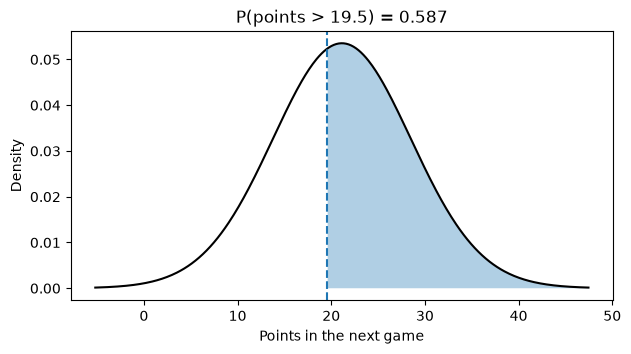

In [7]:
import math

import numpy as np
from scipy import stats


def nig_from_sample(pts):
    """Posterior of (mean, variance) after a flat prior and these games."""
    values = pts.dropna().to_numpy(dtype=float)
    if len(values) < 2:
        raise ValueError("need at least two games")
    center = float(values.mean())
    sse = float(np.sum((values - center) ** 2))
    n = len(values)
    return {"kappa": n, "mu": center, "alpha": (n - 1) / 2, "beta": 0.5 * sse}


def nig_update(state, pts):
    """Conjugate update for new games."""
    values = pts.dropna().to_numpy(dtype=float)
    if len(values) == 0:
        raise ValueError("no observed games")
    n = len(values)
    ybar = float(values.mean())
    sse = float(np.sum((values - ybar) ** 2))
    kappa = state["kappa"] + n
    mu = (state["kappa"] * state["mu"] + n * ybar) / kappa
    alpha = state["alpha"] + n / 2
    beta = (
        state["beta"]
        + 0.5 * sse
        + (state["kappa"] * n) / (2 * kappa) * (ybar - state["mu"]) ** 2
    )
    return {"kappa": kappa, "mu": mu, "alpha": alpha, "beta": beta}


def predictive_student_t(state):
    """Location, degrees of freedom, and scale of the next-game distribution."""
    if state["alpha"] <= 0 or state["beta"] <= 0 or state["kappa"] <= 0:
        raise ValueError("predictive scale is undefined")
    degrees = 2 * state["alpha"]
    loc = state["mu"]
    scale = math.sqrt((state["beta"] / state["alpha"]) * (1 + 1 / state["kappa"]))
    return degrees, loc, scale


chrono = data.sort_values(["game_date", "game_id"], kind="mergesort")
prior_pts = chrono.loc[chrono["season_year"] == "2025-26", "pts"]
season_pts = chrono.loc[chrono["season_year"] == "2026-27", "pts"].dropna()
if season_pts.empty:
    raise ValueError(f"no 2026-27 points for {PLAYER_NAME}")

posterior = nig_update(nig_from_sample(prior_pts), season_pts)
oneshot = nig_from_sample(pd.concat([prior_pts.dropna(), season_pts]))
for key in ("kappa", "mu", "alpha", "beta"):
    if abs(posterior[key] - oneshot[key]) > 1e-6:
        raise AssertionError(f"{key} disagrees between the sequential update and the pooled sample")

degrees, loc, scale = predictive_student_t(posterior)
pred_sd = scale * math.sqrt(degrees / (degrees - 2))
p_over = float(stats.t.sf(LINE, degrees, loc=loc, scale=scale))
lo, hi = stats.t.interval(0.95, degrees, loc=loc, scale=scale)
q10, q50, q90 = stats.t.ppf([0.10, 0.50, 0.90], degrees, loc=loc, scale=scale)

sigma2 = float(prior_pts.dropna().var(ddof=1))
n_total = posterior["kappa"]
known_sd = math.sqrt(sigma2 * (1 + 1 / n_total))
p_known = float(stats.norm.sf(LINE, loc=loc, scale=known_sd))

print(f"Next game ~ Student-t(df={degrees:.0f}, center={loc:.2f}, scale={scale:.2f})")
print(f"Predictive sd = {pred_sd:.2f}")
print(f"10th / 50th / 90th percentile: {q10:.1f} / {q50:.1f} / {q90:.1f}")
print(f"95% interval for the next game: [{lo:.2f}, {hi:.2f}]")
print(f"P(points > {LINE:.1f}) = {p_over:.3f}")
print(f"Variance fixed at the 2025-26 estimate: sd {known_sd:.2f}, P(points > {LINE:.1f}) = {p_known:.3f}")

xs = np.linspace(loc - 3.5 * pred_sd, loc + 3.5 * pred_sd, 400)
density = stats.t.pdf(xs, degrees, loc=loc, scale=scale)
fig, ax = plt.subplots(figsize=(7, 3.5))
ax.plot(xs, density, color="black")
ax.fill_between(xs, density, where=xs > LINE, alpha=0.35)
ax.axvline(LINE, color="C0", linestyle="--")
ax.set_xlabel("Points in the next game")
ax.set_ylabel("Density")
ax.set_title(f"P(points > {LINE:.1f}) = {p_over:.3f}")
plt.show()

### Bayesian Regression

The regression predicts points from information known before the game. Last game's minutes, field-goal attempts, and free-throw attempts describe the recent role. Rest is the number of days since his previous game this season. Opponent context is that opponent's average defensive rating over their previous 10 games. Home or away is the remaining pregame indicator. Same-game minutes and shot attempts are not predictors, and the 2026-27 games are not in the fit.

Predictors are standardized. Each slope has a normal prior with standard deviation 2.5 residual standard deviations, which is weak. Residual variance has an inverse-gamma prior with mean 50. Results below are converted back to original units. A higher opponent defensive rating means that opponent has been allowing more points.

The career fit is driven largely by the move from a small role to a large one. The 2024-25 and 2025-26 fit asks whether last game's role still changes the prediction once that larger role is already the baseline.

In [8]:
import math

import numpy as np
from scipy import stats

FEATURES = [
    "min_lag_1",
    "fga_lag_1",
    "fta_lag_1",
    "rest_days",
    "opp_def_prior",
    "is_home",
]
SLOPE_PRIOR_SD = 2.5
INTERCEPT_PRIOR_SD = 100.0
PRIOR_A = 2.0
PRIOR_B = 50.0


def bayesian_regression(frame):
    """Normal-inverse-gamma regression. Slopes use a weak prior on standardized predictors."""
    y = frame["pts"].to_numpy(dtype=float)
    raw = frame[FEATURES].to_numpy(dtype=float)
    center = raw.mean(axis=0)
    scale = raw.std(axis=0, ddof=0)
    if np.any(~np.isfinite(scale)) or np.any(scale <= 0):
        raise ValueError("a predictor has no variation")
    design = np.column_stack([np.ones(len(frame)), (raw - center) / scale])
    n_rows, n_coef = design.shape
    prior_precision = np.full(n_coef, 1 / SLOPE_PRIOR_SD**2)
    prior_precision[0] = 1 / INTERCEPT_PRIOR_SD**2
    lam0 = np.diag(prior_precision)
    lam = lam0 + design.T @ design
    np.linalg.cholesky(lam)
    coef = np.linalg.solve(lam, design.T @ y)
    a_n = PRIOR_A + n_rows / 2
    b_n = PRIOR_B + 0.5 * float(y @ y - coef @ lam @ coef)
    if not math.isfinite(b_n) or b_n <= 0 or a_n <= 1:
        raise ValueError("posterior variance is undefined")
    return {
        "n": n_rows,
        "center": center,
        "scale": scale,
        "coef": coef,
        "lam": lam,
        "a": a_n,
        "b": b_n,
        "df": 2 * a_n,
    }


def contrast_interval(fit, delta):
    """Posterior mean and 95% interval for a change in the raw predictors."""
    contrast = np.zeros(len(fit["coef"]))
    contrast[1:] = np.asarray(delta, dtype=float) / fit["scale"]
    estimate = float(contrast @ fit["coef"])
    spread = math.sqrt(
        (fit["b"] / fit["a"]) * float(contrast @ np.linalg.solve(fit["lam"], contrast))
    )
    critical = float(stats.t.ppf(0.975, fit["df"]))
    return estimate, estimate - critical * spread, estimate + critical * spread


def predictive_at(fit, raw_row):
    z_score = (np.asarray(raw_row, dtype=float) - fit["center"]) / fit["scale"]
    row = np.concatenate([[1.0], z_score])
    loc = float(row @ fit["coef"])
    scale = math.sqrt(
        (fit["b"] / fit["a"]) * (1 + float(row @ np.linalg.solve(fit["lam"], row)))
    )
    p_over = float(stats.t.sf(LINE, fit["df"], loc=loc, scale=scale))
    return loc, p_over


player = data.sort_values(["game_date", "game_id"], kind="mergesort").copy()
player["game_date"] = pd.to_datetime(player["game_date"])
for source, lagged in (("minutes", "min_lag_1"), ("fga", "fga_lag_1"), ("fta", "fta_lag_1")):
    player[lagged] = pd.to_numeric(player[source], errors="coerce").shift(1)
player["rest_days"] = player.groupby("season_year", sort=False)["game_date"].diff().dt.days
player["is_home"] = player["matchup"].astype(str).str.contains("vs", case=False).astype(float)

teams = (
    df[["team_id", "game_id", "game_date", "team_def_rating"]]
    .drop_duplicates(["team_id", "game_id"])
    .sort_values(["team_id", "game_date", "game_id"], kind="mergesort")
)
teams["team_def_rating"] = pd.to_numeric(teams["team_def_rating"], errors="coerce")
prior_defense = teams.groupby("team_id", sort=False)["team_def_rating"].shift(1)
teams["opp_def_prior"] = (
    prior_defense.groupby(teams["team_id"], sort=False)
    .rolling(10, min_periods=3)
    .mean()
    .reset_index(level=0, drop=True)
)
player = player.merge(
    teams[["game_id", "team_id", "opp_def_prior"]].rename(columns={"team_id": "opp_team_id"}),
    on=["game_id", "opp_team_id"],
    how="left",
    validate="many_to_one",
)

history = player.loc[player["season_year"] != "2026-27"].copy()
complete = history.dropna(subset=FEATURES + ["pts"])
played = complete.loc[pd.to_numeric(complete["minutes"], errors="coerce") > 0].copy()
n_dropped = len(history) - len(played)
if played.empty:
    raise ValueError(f"no complete pre-2026-27 games for {PLAYER_NAME}")
print(
    f"Left out {n_dropped} pre-2026-27 games with missing predictors, missing points, or zero minutes."
)

LABELS = {
    "min_lag_1": "lagged minutes, per minute",
    "fga_lag_1": "lagged field-goal attempts, per attempt",
    "fta_lag_1": "lagged free-throw attempts, per attempt",
    "rest_days": "rest, per extra day",
    "opp_def_prior": "softer opponent defense, per rating point",
    "is_home": "home instead of away",
}


def report(title, frame):
    fit = bayesian_regression(frame)
    print(f"\n{title}: {fit['n']} games")
    for index, name in enumerate(FEATURES):
        estimate, low, high = contrast_interval(fit, np.eye(len(FEATURES))[index])
        print(f"  {LABELS[name]}: {estimate:+.2f}  [{low:+.2f}, {high:+.2f}]")
    role = np.array([5.0, 3.0, 1.0, 0.0, 0.0, 0.0])
    defense = np.array([0.0, 0.0, 0.0, 0.0, 5.0, 0.0])
    for label, delta in (
        ("role +5 minutes, +3 FGA, +1 FTA", role),
        ("opponent defense 5 points softer", defense),
    ):
        estimate, low, high = contrast_interval(fit, delta)
        print(f"  {label}: {estimate:+.2f} points  [{low:+.2f}, {high:+.2f}]")
    return fit

career = report("Career before 2026-27", played)
recent = played.loc[played["season_year"].isin(["2024-25", "2025-26"])].copy()
report("2024-25 and 2025-26 only", recent)

baseline = played.loc[played["season_year"] == "2025-26", FEATURES].mean().to_numpy(dtype=float)
base_mean, base_over = predictive_at(career, baseline)
role_mean, role_over = predictive_at(career, baseline + np.array([5.0, 3.0, 1.0, 0.0, 0.0, 0.0]))
defense_mean, defense_over = predictive_at(
    career, baseline + np.array([0.0, 0.0, 0.0, 0.0, 5.0, 0.0])
)
print("\nCareer model at his 2025-26 average role")
print(f"  baseline: {base_mean:.2f} points, P(points > {LINE:.1f}) = {base_over:.3f}")
print(f"  larger role: {role_mean:.2f} points, P(points > {LINE:.1f}) = {role_over:.3f}")
print(
    f"  softer defense: {defense_mean:.2f} points, P(points > {LINE:.1f}) = {defense_over:.3f}"
)

Left out 9 pre-2026-27 games with missing predictors, missing points, or zero minutes.

Career before 2026-27: 469 games
  lagged minutes, per minute: +0.07  [-0.12, +0.26]
  lagged field-goal attempts, per attempt: +0.19  [-0.00, +0.38]
  lagged free-throw attempts, per attempt: +0.04  [-0.17, +0.26]
  rest, per extra day: -0.12  [-0.55, +0.32]
  softer opponent defense, per rating point: +0.19  [+0.05, +0.33]
  home instead of away: -0.79  [-2.23, +0.65]
  role +5 minutes, +3 FGA, +1 FTA: +0.96 points  [+0.19, +1.73]
  opponent defense 5 points softer: +0.95 points  [+0.23, +1.67]

2024-25 and 2025-26 only: 146 games
  lagged minutes, per minute: -0.05  [-0.34, +0.24]
  lagged field-goal attempts, per attempt: +0.04  [-0.31, +0.38]
  lagged free-throw attempts, per attempt: -0.03  [-0.38, +0.32]
  rest, per extra day: -0.01  [-0.49, +0.47]
  softer opponent defense, per rating point: +0.02  [-0.20, +0.24]
  home instead of away: +0.48  [-1.82, +2.78]
  role +5 minutes, +3 FGA, +1 FTA

### Hierarchical Bayesian Model

This combines partial pooling with the pregame regression. For game *g* by player *i*:

pointsᵢg = shared pregame regression + position effect + team effect + player effect + noise

Position, team, and player effects have zero-centered normal priors. Their prior precisions act like pseudo-games: 20 for position, 20 for team, and 10 for player. A one-game player's identity estimate is therefore pulled strongly toward the position-and-team baseline; an established player's estimate is driven mostly by his own history. A player unseen in training receives no player effect but still receives the shared role, position, and team effects.

The common predictors are lagged minutes, FGA, FTA, rest, opponent defensive context, and home court. This separates role from player identity: changing expected opportunities moves the shared regression component without pretending that the player's underlying scoring level changed permanently.

The model is fitted on 2024-25 and 2025-26 only. The 2026-27 games remain untouched. The posterior and predictive distribution are available analytically because every coefficient has a normal prior and the residual variance has an inverse-gamma prior. This is a deliberately simple hierarchy; the pseudo-game strengths are modeling assumptions, not values selected on the holdout.

In [9]:
from scipy import sparse
from scipy.sparse.linalg import splu

HIER_FEATURES = [
    "min_lag_1",
    "fga_lag_1",
    "fta_lag_1",
    "rest_days",
    "opp_def_prior",
    "is_home",
]
HIER_TRAIN_SEASONS = ["2024-25", "2025-26"]
POSITION_PSEUDO_GAMES = 20.0
TEAM_PSEUDO_GAMES = 20.0
PLAYER_PSEUDO_GAMES = 10.0


def hierarchical_frame(games):
    """Build causal game-level predictors for every player."""
    frame = games.copy()
    frame["game_date"] = pd.to_datetime(frame["game_date"])
    frame = frame.sort_values(
        ["player_id", "game_date", "game_id"], kind="mergesort"
    )
    for source, lagged in (
        ("minutes", "min_lag_1"),
        ("fga", "fga_lag_1"),
        ("fta", "fta_lag_1"),
    ):
        numeric = pd.to_numeric(frame[source], errors="coerce")
        frame[lagged] = numeric.groupby(frame["player_id"], sort=False).shift(1)
    frame["rest_days"] = (
        frame.groupby(["player_id", "season_year"], sort=False)["game_date"]
        .diff()
        .dt.days
    )
    frame["is_home"] = (
        frame["matchup"].astype(str).str.contains("vs", case=False).astype(float)
    )

    teams = (
        frame[["team_id", "game_id", "game_date", "team_def_rating"]]
        .drop_duplicates(["team_id", "game_id"])
        .sort_values(["team_id", "game_date", "game_id"], kind="mergesort")
    )
    teams["team_def_rating"] = pd.to_numeric(
        teams["team_def_rating"], errors="coerce"
    )
    prior_defense = teams.groupby("team_id", sort=False)["team_def_rating"].shift(1)
    teams["opp_def_prior"] = (
        prior_defense.groupby(teams["team_id"], sort=False)
        .rolling(10, min_periods=3)
        .mean()
        .reset_index(level=0, drop=True)
    )
    opponent = teams[["game_id", "team_id", "opp_def_prior"]].rename(
        columns={"team_id": "opp_team_id"}
    )
    return frame.merge(
        opponent,
        on=["game_id", "opp_team_id"],
        how="left",
        validate="many_to_one",
    )


def category_map(values):
    unique = sorted(pd.Series(values).dropna().unique().tolist())
    return {value: index for index, value in enumerate(unique)}


def one_hot(values, mapping):
    row = np.arange(len(values))
    column = np.array([mapping[value] for value in values])
    return sparse.csr_matrix(
        (np.ones(len(values)), (row, column)),
        shape=(len(values), len(mapping)),
    )


def fit_hierarchical_points(frame):
    """Conjugate Bayesian regression with position, team, and player effects."""
    raw = frame[HIER_FEATURES].to_numpy(dtype=float)
    center = raw.mean(axis=0)
    scale = raw.std(axis=0, ddof=0)
    if np.any(~np.isfinite(scale)) or np.any(scale <= 0):
        raise ValueError("a hierarchical predictor has no variation")

    position_map = category_map(frame["pos"].astype(str))
    team_map = category_map(frame["team_id"])
    player_map = category_map(frame["player_id"])
    common = sparse.csr_matrix(
        np.column_stack([np.ones(len(frame)), (raw - center) / scale])
    )
    design = sparse.hstack(
        [
            common,
            one_hot(frame["pos"].astype(str), position_map),
            one_hot(frame["team_id"], team_map),
            one_hot(frame["player_id"], player_map),
        ],
        format="csc",
    )

    n_common = 1 + len(HIER_FEATURES)
    precision = np.concatenate(
        [
            [1e-6],
            np.full(len(HIER_FEATURES), 1 / 2.5**2),
            np.full(len(position_map), POSITION_PSEUDO_GAMES),
            np.full(len(team_map), TEAM_PSEUDO_GAMES),
            np.full(len(player_map), PLAYER_PSEUDO_GAMES),
        ]
    )
    posterior_precision = (
        design.T @ design + sparse.diags(precision, format="csc")
    ).tocsc()
    factor = splu(posterior_precision)
    y = frame["pts"].to_numpy(dtype=float)
    xty = np.asarray(design.T @ y).ravel()
    coef = factor.solve(xty)
    alpha = 2.0 + len(frame) / 2
    beta = 50.0 + 0.5 * float(y @ y - coef @ xty)
    if not np.isfinite(coef).all() or not math.isfinite(beta) or beta <= 0:
        raise ValueError("hierarchical posterior is not finite")

    return {
        "n": len(frame),
        "center": center,
        "scale": scale,
        "coef": coef,
        "factor": factor,
        "alpha": alpha,
        "beta": beta,
        "df": 2 * alpha,
        "position_map": position_map,
        "team_map": team_map,
        "player_map": player_map,
        "n_common": n_common,
    }


def hierarchical_row(fit, raw, position, team_id, player_id=None):
    """Create a prediction row; unseen identities receive a zero player effect."""
    n_position = len(fit["position_map"])
    n_team = len(fit["team_map"])
    row = np.zeros(len(fit["coef"]))
    row[0] = 1.0
    row[1 : fit["n_common"]] = (
        np.asarray(raw, dtype=float) - fit["center"]
    ) / fit["scale"]
    position = str(position)
    if position in fit["position_map"]:
        row[fit["n_common"] + fit["position_map"][position]] = 1.0
    if team_id in fit["team_map"]:
        row[
            fit["n_common"] + n_position + fit["team_map"][team_id]
        ] = 1.0
    if player_id in fit["player_map"]:
        row[
            fit["n_common"]
            + n_position
            + n_team
            + fit["player_map"][player_id]
        ] = 1.0
    return row


def hierarchical_predict(fit, row, line=LINE):
    """Posterior predictive center, scale, and over probability."""
    loc = float(row @ fit["coef"])
    leverage = float(row @ fit["factor"].solve(row))
    scale = math.sqrt(
        (fit["beta"] / fit["alpha"]) * (1.0 + leverage)
    )
    probability = float(
        stats.t.sf(line, fit["df"], loc=loc, scale=scale)
    )
    return {"mean": loc, "scale": scale, "p_over": probability}


hier_data = hierarchical_frame(df)
required = HIER_FEATURES + ["pts", "player_id", "pos", "team_id"]
train_candidates = hier_data.loc[
    hier_data["season_year"].isin(HIER_TRAIN_SEASONS)
].copy()
hier_train = train_candidates.dropna(subset=required).copy()
hier_train = hier_train.loc[
    pd.to_numeric(hier_train["minutes"], errors="coerce") > 0
].copy()
print(
    f"Training rows: {len(hier_train):,}; excluded incomplete/zero-minute rows: "
    f"{len(train_candidates) - len(hier_train):,}; players: "
    f"{hier_train['player_id'].nunique()}"
)
if (hier_train["season_year"] == "2026-27").any():
    raise AssertionError("2026-27 leaked into the hierarchy")

hier_fit = fit_hierarchical_points(hier_train)
latest = (
    hier_data.loc[hier_data["player_name"] == PLAYER_NAME]
    .sort_values(["game_date", "game_id"])
    .iloc[-1]
)
player_id = latest["player_id"]
role = hier_train.loc[
    (hier_train["player_id"] == player_id)
    & (hier_train["season_year"] == "2025-26"),
    HIER_FEATURES,
].mean().to_numpy(dtype=float)
if not np.isfinite(role).all():
    raise ValueError(f"no complete 2025-26 role baseline for {PLAYER_NAME}")

player_row = hierarchical_row(
    hier_fit, role, latest["pos"], latest["team_id"], player_id
)
new_player_row = hierarchical_row(
    hier_fit, role, latest["pos"], latest["team_id"], player_id=None
)
larger_role_row = hierarchical_row(
    hier_fit,
    role + np.array([5.0, 3.0, 1.0, 0.0, 0.0, 0.0]),
    latest["pos"],
    latest["team_id"],
    player_id,
)
player_prediction = hierarchical_predict(hier_fit, player_row)
peer_prediction = hierarchical_predict(hier_fit, new_player_row)
role_prediction = hierarchical_predict(hier_fit, larger_role_row)

n_position = len(hier_fit["position_map"])
n_team = len(hier_fit["team_map"])
player_offset = hier_fit["n_common"] + n_position + n_team
player_effect = hier_fit["coef"][
    player_offset + hier_fit["player_map"][player_id]
]
if abs(
    player_prediction["mean"] - peer_prediction["mean"] - player_effect
) > 1e-8:
    raise AssertionError("player partial-pooling effect is not isolated correctly")

print(f"\n{PLAYER_NAME} at his 2025-26 average role")
print(
    f"  unseen-player position/team baseline: {peer_prediction['mean']:.2f} points, "
    f"P(over {LINE:.1f}) = {peer_prediction['p_over']:.3f}"
)
print(
    f"  with learned player effect ({player_effect:+.2f}): "
    f"{player_prediction['mean']:.2f} points, "
    f"P(over {LINE:.1f}) = {player_prediction['p_over']:.3f}"
)
print(
    f"  larger role (+5 minutes, +3 FGA, +1 FTA): "
    f"{role_prediction['mean']:.2f} points, "
    f"P(over {LINE:.1f}) = {role_prediction['p_over']:.3f}"
)
print(
    f"  role change: {role_prediction['mean'] - player_prediction['mean']:+.2f} points"
)

player_summary = (
    hier_train.groupby(["player_id", "player_name"], as_index=False)
    .agg(games=("pts", "size"), raw_mean=("pts", "mean"))
)
last_context = (
    hier_train.sort_values(["game_date", "game_id"])
    .groupby("player_id", sort=False)
    .tail(1)
    .set_index("player_id")
)
pooled = []
for record in player_summary.itertuples():
    context = last_context.loc[record.player_id]
    average_role = hier_train.loc[
        hier_train["player_id"] == record.player_id, HIER_FEATURES
    ].mean().to_numpy(dtype=float)
    row = hierarchical_row(
        hier_fit,
        average_role,
        context["pos"],
        context["team_id"],
        record.player_id,
    )
    pooled.append(hierarchical_predict(hier_fit, row)["mean"])
player_summary["pooled_mean"] = pooled
player_summary["shrinkage"] = (
    player_summary["pooled_mean"] - player_summary["raw_mean"]
)
print("\nSmallest samples: raw mean -> partially pooled prediction")
print(
    player_summary.sort_values(["games", "player_name"])
    .head(10)[["player_name", "games", "raw_mean", "pooled_mean", "shrinkage"]]
    .round(2)
    .to_string(index=False)
)

Training rows: 51,632; excluded incomplete/zero-minute rows: 1,325; players: 679

Julius Randle at his 2025-26 average role
  unseen-player position/team baseline: 14.90 points, P(over 19.5) = 0.226
  with learned player effect (+7.56): 22.46 points, P(over 19.5) = 0.685
  larger role (+5 minutes, +3 FGA, +1 FTA): 23.99 points, P(over 19.5) = 0.768
  role change: +1.53 points



Smallest samples: raw mean -> partially pooled prediction
     player_name  games  raw_mean  pooled_mean  shrinkage
  Chucky Hepburn      1       0.0         5.81       5.81
   Jesse Edwards      1       0.0         3.35       3.35
 Lawson Lovering      1      11.0         8.54      -2.46
Mouhamadou Gueye      1      11.0         9.07      -1.93
    Noa Essengue      1       0.0         5.97       5.97
  Quincy Olivari      1       0.0         4.87       4.87
      Taze Moore      1       2.0         7.61       5.61
    Yuri Collins      1       0.0         6.70       6.70
     Braxton Key      2       1.5         5.53       4.03
     Daishen Nix      2       0.5         3.64       3.14
